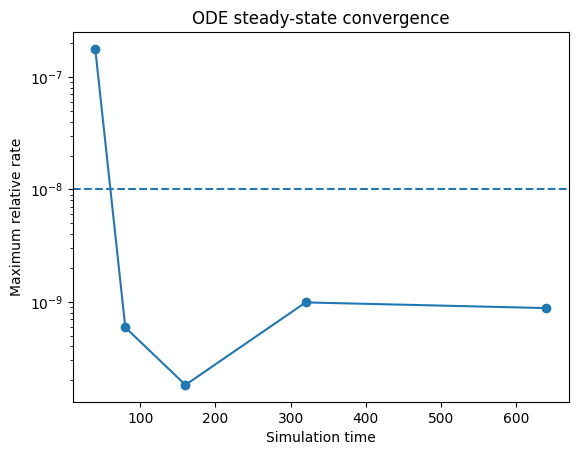

In [7]:
import numpy as np
import matplotlib.pyplot as plt

T_values = np.array([40, 80, 160, 320, 640])
max_rel_rate = np.array([
    1.779e-7,
    5.902e-10,
    1.816e-10,
    9.855e-10,
    8.771e-10
])

plt.semilogy(T_values, max_rel_rate, marker="o")
plt.axhline(1e-8, linestyle="--")
plt.xlabel("Simulation time")
plt.ylabel("Maximum relative rate")
plt.title("ODE steady-state convergence")
plt.show()

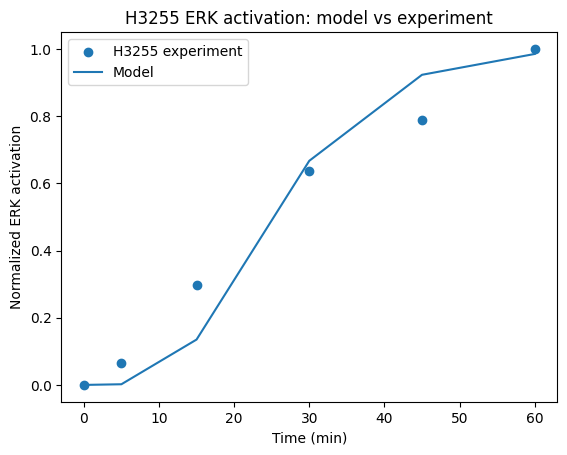

In [8]:
exp_t = np.array([0, 5, 15, 30, 45, 60])
exp_erk = np.array([0.000, 0.064, 0.298, 0.638, 0.787, 1.000])

model_t = np.array([0, 5, 15, 30, 45, 60])
model_erk = np.array([0.000, 0.002, 0.135, 0.667, 0.923, 0.985])

plt.scatter(exp_t, exp_erk, label="H3255 experiment")
plt.plot(model_t, model_erk, label="Model")
plt.xlabel("Time (min)")
plt.ylabel("Normalized ERK activation")
plt.title("H3255 ERK activation: model vs experiment")
plt.legend()
plt.show()

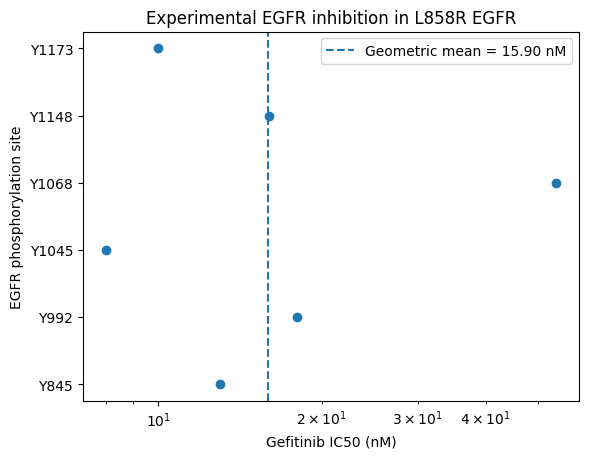

In [9]:
sites = ["Y845", "Y992", "Y1045", "Y1068", "Y1148", "Y1173"]
ic50 = np.array([13, 18, 8, 54, 16, 10])

plt.scatter(ic50, sites)
plt.axvline(15.90, linestyle="--", label="Geometric mean = 15.90 nM")

plt.xscale("log")
plt.xlabel("Gefitinib IC50 (nM)")
plt.ylabel("EGFR phosphorylation site")
plt.title("Experimental EGFR inhibition in L858R EGFR")
plt.legend()
plt.show()

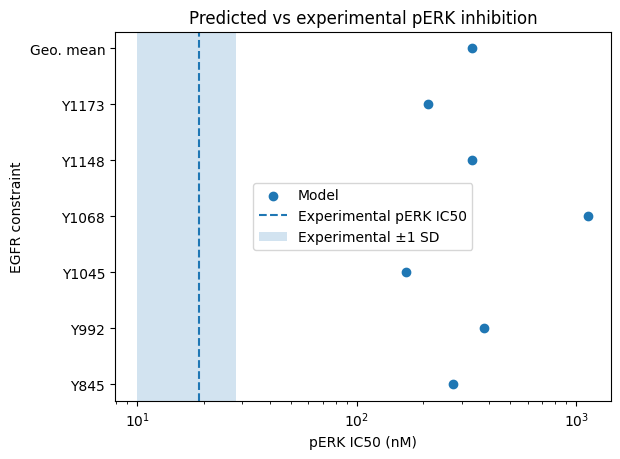

In [10]:
sites = ["Y845", "Y992", "Y1045", "Y1068", "Y1148", "Y1173", "Geo. mean"]

model_ic50 = np.array([
    273, 378, 168, 1134, 336, 210, 333.96
])

plt.scatter(model_ic50, sites, label="Model")

plt.axvline(19, linestyle="--", label="Experimental pERK IC50")
plt.axvspan(10, 28, alpha=0.2, label="Experimental ±1 SD")

plt.xscale("log")
plt.xlabel("pERK IC50 (nM)")
plt.ylabel("EGFR constraint")
plt.title("Predicted vs experimental pERK inhibition")
plt.legend()
plt.show()

G: min=0.000000, max=1.000000, range=1.000000, CV=1.416634
EGFR*: min=0.666667, max=0.666667, range=0.000000, CV=0.000000
ERK*: min=1.015873, max=1.015873, range=0.000000, CV=0.000000
P: min=2.031746, max=2.031746, range=0.000000, CV=0.000000


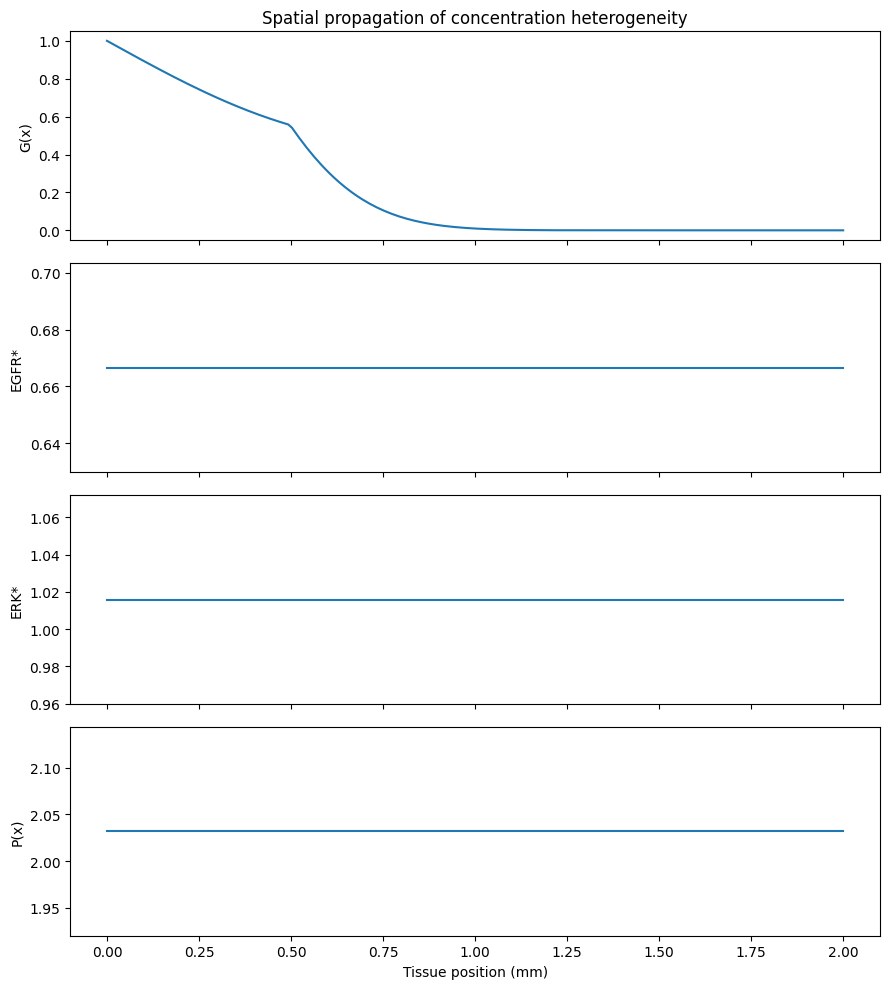

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Spatial domain
L = 0.2
nx = 200
x = np.linspace(0, L, nx)
dx = x[1] - x[0]

# Solver tolerances
rtol = 1e-9
atol = 1e-12

# Validated diffusion model
D1 = 5e-7
D2 = 1e-7
D3 = 5e-7

boundary_1 = 0.05
boundary_2 = 0.12

C_source = 1.0

T_diffusion = 3600
nt = 30000
dt = T_diffusion / nt

# Load validated exp04b outputs
G = np.load("saved_parameters/exp04b_G.npy")
T_steady = np.load("saved_parameters/exp04b_T_steady.npy")

# Initial state vector
y0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

# Parameter dictionary
params_baseline = {
    "EGF" : 1.0,
    "IC_50" : 0.3,
    "n" : 1.0,
    "G" : 0.0,
    "k_EGF" : 1.0,
    "k_EGFR_off" : 0.5,
    "k_RAS" : 1.0,
    "k_RAS_off" : 0.5,
    "k_RAF" : 1.0,
    "k_RAF_off" : 0.5,
    "k_MEK" : 1.0,
    "k_MEK_off" : 0.5,
    "k_ERK" : 1.0,
    "k_ERK_off" : 0.5,
    "k_T" : 1.0,
    "k_deg" : 0.5,
    "k_P" : 1.0,
    "k_loss" : 0.5,
}

# ODE Signaling Function
def pathway(t, y, params):
    # External factors
    EGF = params["EGF"]
    G = params["G"]
    IC_50 = params["IC_50"]
    n = params["n"]

    # Extract activated protein and Cyclin D/Proliferation rates from array y
    EGFR_star, RAS_star, RAF_star, MEK_star, ERK_star, CycD, P = y

    # Total protein concentrations
    EGFR_tot = 1.0
    RAS_tot = 1.0
    RAF_tot = 1.0
    MEK_tot = 1.0
    ERK_tot = 1.0

    # Rate constants (normalized currently)
    k_EGF = params["k_EGF"]
    k_EGFR_off = params["k_EGFR_off"]

    k_RAS = params["k_RAS"]
    k_RAS_off = params["k_RAS_off"]

    k_RAF = params["k_RAF"]
    k_RAF_off = params["k_RAF_off"]

    k_MEK = params["k_MEK"]
    k_MEK_off = params["k_MEK_off"]

    k_ERK = params["k_ERK"]
    k_ERK_off = params["k_ERK_off"]

    k_T = params["k_T"]
    k_deg = params["k_deg"]

    k_P = params["k_P"]
    k_loss = params["k_loss"]

    # Calculating derivatives
    EGFR_gefit = 1 / (1 + (G / IC_50) ** n)
    EGFR_act = k_EGF * EGF * (EGFR_tot - EGFR_star) * EGFR_gefit
    EGFR_dect = k_EGFR_off * EGFR_star

    dEGFR = EGFR_act - EGFR_dect

    RAS_act = k_RAS * EGFR_star * (RAS_tot - RAS_star)
    RAS_dect = k_RAS_off * RAS_star

    dRAS = RAS_act - RAS_dect

    RAF_act = k_RAF * RAS_star * (RAF_tot - RAF_star)
    RAF_dect = k_RAF_off * RAF_star

    dRAF = RAF_act - RAF_dect

    MEK_act = k_MEK * RAF_star * (MEK_tot - MEK_star)
    MEK_dect = k_MEK_off * MEK_star

    dMEK = MEK_act - MEK_dect

    ERK_act = k_ERK * MEK_star * (ERK_tot - ERK_star)
    ERK_dect = k_ERK_off * ERK_star

    dERK = ERK_act - ERK_dect

    CycD_act = k_T * ERK_star
    CycD_dect = k_deg * CycD

    dCycD = CycD_act - CycD_dect

    P_act = k_P * CycD
    P_dect = k_loss * P

    dP = P_act - P_dect

    return [dEGFR, dRAS, dRAF, 
                dMEK, dERK, dCycD, dP]

# Building baseline solutions array
solutions_baseline = np.zeros((7, nx))

for i in range(nx):
    G_local = G[i]

    sol = solve_ivp(
        pathway,
        [0, T_steady],
        y0,
        args=(params_baseline,),
        rtol=rtol,
        atol=atol
    )

    solutions_baseline[:, i] = sol.y[:, -1]

EGFR = solutions_baseline[0]
ERK = solutions_baseline[5]
P = solutions_baseline[6]

# Your existing arrays
# x = spatial coordinate
# G = final diffusion profile
# EGFR = spatial EGFR* profile
# ERK = spatial ERK* profile
# P = spatial proliferation profile

variables = {
    "G": G,
    "EGFR*": EGFR,
    "ERK*": ERK,
    "P": P
}

for name, arr in variables.items():
    mean = np.mean(arr)
    std = np.std(arr)
    cv = std / mean if mean != 0 else np.nan
    print(
        f"{name}: "
        f"min={arr.min():.6f}, "
        f"max={arr.max():.6f}, "
        f"range={arr.max()-arr.min():.6f}, "
        f"CV={cv:.6f}"
    )

fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True)

axes[0].plot(x * 10, G)
axes[0].set_ylabel("G(x)")
axes[0].set_title("Spatial propagation of concentration heterogeneity")

axes[1].plot(x * 10, EGFR)
axes[1].set_ylabel("EGFR*")

axes[2].plot(x * 10, ERK)
axes[2].set_ylabel("ERK*")

axes[3].plot(x * 10, P)
axes[3].set_ylabel("P(x)")
axes[3].set_xlabel("Tissue position (mm)")

plt.tight_layout()
plt.show()

In [12]:
cv_G = np.std(G) / np.mean(G)

for name, arr in {
    "EGFR*": EGFR,
    "ERK*": ERK,
    "P": P
}.items():
    cv = np.std(arr) / np.mean(arr)
    print(f"{name}: {cv/cv_G:.4f} of input CV")

EGFR*: 0.0000 of input CV
ERK*: 0.0000 of input CV
P: 0.0000 of input CV


In [13]:
def run_spatial_signaling(G_profile, params, T=80):
    EGFR_ss = np.zeros(len(G_profile))
    RAS_ss = np.zeros(len(G_profile))
    RAF_ss = np.zeros(len(G_profile))
    MEK_ss = np.zeros(len(G_profile))
    ERK_ss = np.zeros(len(G_profile))
    CycD_ss = np.zeros(len(G_profile))
    P_ss = np.zeros(len(G_profile))

    for i, G_local in enumerate(G_profile):

        local_params = params.copy()
        local_params["G"] = G_local

        sol = solve_ivp(
            pathway,
            [0, T],
            np.zeros(7),
            args=(local_params,),
            rtol=1e-9,
            atol=1e-12
        )

        final = sol.y[:, -1]

        EGFR_ss[i] = final[0]
        RAS_ss[i] = final[1]
        RAF_ss[i] = final[2]
        MEK_ss[i] = final[3]
        ERK_ss[i] = final[4]
        CycD_ss[i] = final[5]
        P_ss[i] = final[6]

    return (
        EGFR_ss,
        RAS_ss,
        RAF_ss,
        MEK_ss,
        ERK_ss,
        CycD_ss,
        P_ss
    )

In [14]:
(
    EGFR_spatial,
    RAS_spatial,
    RAF_spatial,
    MEK_spatial,
    ERK_spatial,
    CycD_spatial,
    P_spatial
) = run_spatial_signaling(G, params_baseline, T=80)

In [15]:
variables = {
    "G": G,
    "EGFR*": EGFR_spatial,
    "ERK*": ERK_spatial,
    "P": P_spatial
}

for name, arr in variables.items():
    mean = np.mean(arr)
    std = np.std(arr)
    cv = std / mean if mean != 0 else np.nan

    print(
        f"{name}: "
        f"min={arr.min():.6f}, "
        f"max={arr.max():.6f}, "
        f"range={arr.max()-arr.min():.6f}, "
        f"CV={cv:.6f}"
    )

G: min=0.000000, max=1.000000, range=1.000000, CV=1.416634
EGFR*: min=0.315789, max=0.666667, range=0.350877, CV=0.228617
ERK*: min=0.482412, max=0.507937, range=0.025524, CV=0.016838
P: min=1.929648, max=2.031746, range=0.102098, CV=0.016838


In [16]:
params = params_baseline.copy()
params["IC_50"] = 15.90 / 3

def get_ERK_ss(G_value, params, T=80):
    local_params = params.copy()
    local_params["G"] = G_value

    sol = solve_ivp(
        pathway,
        [0, T],
        np.zeros(7),
        args=(local_params,),
        rtol=1e-9,
        atol=1e-12
    )

    return sol.y[4, -1]

In [17]:
from scipy.optimize import brentq

def model_ERK_IC50(params, G_min=1e-6, G_max=1e5):

    ERK_baseline = get_ERK_ss(0.0, params)

    target = 0.5 * ERK_baseline

    def objective(G):
        return get_ERK_ss(G, params) - target

    return brentq(objective, G_min, G_max)

In [18]:
erk_ic50 = model_ERK_IC50(params)

print(f"Model ERK IC50 = {erk_ic50:.3f} nM")

Model ERK IC50 = 333.900 nM


In [19]:
experimental_EGFR = {
    "Y845": 13,
    "Y992": 18,
    "Y1045": 8,
    "Y1068": 54,
    "Y1148": 16,
    "Y1173": 10
}

experimental_pERK_IC50 = 19.0

In [20]:
results = []

for site, egfr_ic50_exp in experimental_EGFR.items():

    local_params = params_baseline.copy()

    # Convert experimental EGFR IC50
    # to the parameter value required by this model architecture
    local_params["IC_50"] = egfr_ic50_exp / 3

    model_ic50 = model_ERK_IC50(local_params)

    fold_error = model_ic50 / experimental_pERK_IC50

    results.append({
        "Site": site,
        "Experimental EGFR IC50 (nM)": egfr_ic50_exp,
        "Model parameter IC50 (nM)": egfr_ic50_exp / 3,
        "Predicted pERK IC50 (nM)": model_ic50,
        "Fold vs experimental pERK": fold_error
    })

In [29]:
# ------------------------------------------------------------
# Six phosphosite constraints
# ------------------------------------------------------------

results = []

for site, egfr_ic50_exp in experimental_EGFR.items():

    local_params = params.copy()

    local_params["IC_50"] = egfr_ic50_exp / 3
    local_params["n"] = 1.0

    model_ic50 = model_ERK_IC50(local_params)

    fold_error = model_ic50 / experimental_pERK_IC50

    results.append([
        site,
        egfr_ic50_exp,
        egfr_ic50_exp / 3,
        model_ic50,
        fold_error
    ])


# ------------------------------------------------------------
# Print table
# ------------------------------------------------------------

print("\nSITE-SPECIFIC VALIDATION")

print(
    f"{'Site':<8}"
    f"{'Exp EGFR':>12}"
    f"{'Model Param':>14}"
    f"{'Model pERK':>16}"
    f"{'Fold Error':>14}"
)

print("-" * 64)

for row in results:

    site, exp_egfr, model_param, model_perk, fold = row

    print(
        f"{site:<8}"
        f"{exp_egfr:>12.1f}"
        f"{model_param:>14.2f}"
        f"{model_perk:>16.2f}"
        f"{fold:>14.2f}x"
    )


SITE-SPECIFIC VALIDATION
Site        Exp EGFR   Model Param      Model pERK    Fold Error
----------------------------------------------------------------
Y845            13.0          4.33          273.00         14.37x
Y992            18.0          6.00          378.00         19.89x
Y1045            8.0          2.67          168.00          8.84x
Y1068           54.0         18.00         1134.00         59.68x
Y1148           16.0          5.33          336.00         17.68x
Y1173           10.0          3.33          210.00         11.05x


In [27]:
# ------------------------------------------------------------
# Hill coefficient sweep
# ------------------------------------------------------------

hill_values = [0.5, 0.75, 1, 1.25, 1.5, 2, 2.5, 3, 3.5, 4, 5]

hill_results = []

for n_value in hill_values:

    local_params = params_baseline.copy()

    local_params["IC_50"] = 15.90 / 3
    local_params["n"] = n_value

    model_ic50 = model_ERK_IC50(local_params)

    fold_error = model_ic50 / experimental_pERK_IC50

    hill_results.append([
        n_value,
        model_ic50,
        fold_error
    ])


print("\nHILL COEFFICIENT SWEEP")

print(
    f"{'n':<8}"
    f"{'Model pERK IC50':>20}"
    f"{'Fold vs Experiment':>22}"
)

print("-" * 50)

for row in hill_results:

    n_value, model_ic50, fold_error = row

    print(
        f"{n_value:<8.1f}"
        f"{model_ic50:>20.2f}"
        f"{fold_error:>21.2f}x"
    )

experimental_pERK_IC50 = 19.0
experimental_sd = 9.0
experimental_low = 10.0
experimental_high = 28.0


HILL COEFFICIENT SWEEP
n            Model pERK IC50    Fold vs Experiment
--------------------------------------------------
0.5                 21035.70              1107.14x
0.8                  1328.61                69.93x
1.0                   333.90                17.57x
1.2                   145.80                 7.67x
1.5                    83.91                 4.42x
2.0                    42.07                 2.21x
2.5                    27.80                 1.46x
3.0                    21.09                 1.11x
3.5                    17.31                 0.91x
4.0                    14.93                 0.79x
5.0                    12.14                 0.64x


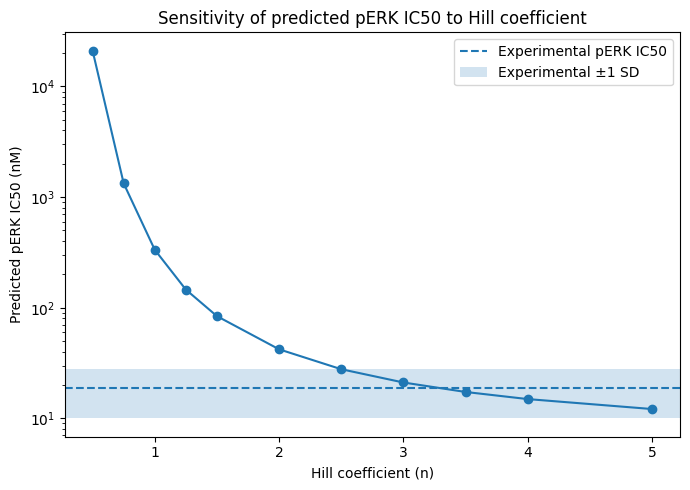

In [28]:
plt.figure(figsize=(7, 5))

plt.plot(
    [row[0] for row in hill_results],
    [row[1] for row in hill_results],
    marker="o"
)

plt.axhline(
    experimental_pERK_IC50,
    linestyle="--",
    label="Experimental pERK IC50"
)

plt.axhspan(
    experimental_low,
    experimental_high,
    alpha=0.2,
    label="Experimental ±1 SD"
)

plt.xlabel("Hill coefficient (n)")
plt.ylabel("Predicted pERK IC50 (nM)")
plt.title("Sensitivity of predicted pERK IC50 to Hill coefficient")

plt.yscale("log")

plt.legend()
plt.tight_layout()
plt.show()